In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from datetime import datetime, timedelta
from helper import fn_plot_tf_hist

In [61]:
RANDOM_STATE=24 # in production we set rs=None it is hard to change everyware
tf.random.set_seed(seed=RANDOM_STATE)
rng=np.random.default_rng(seed=RANDOM_STATE)

EPOCHS=100
ALPHA=0.001 #LEARNING RATE
TEST_SIZE=0.2
N_SAMPLES=1000
BATCH_SIZE=32
params={
    'legend.fontsize':'medium',
    'figure.figsize':(15,6),
    'axes.labelsize':'medium',
    'axes.titlesize':'medium',
    'xtick.labelsize':'medium',  
    'ytick.labelsize':'medium',  
    
}
plt.rcParams.update(params)
CMAP=plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid')

In [62]:
df= pd.read_csv(r"C:\Users\PGCP-AI\Downloads\weatherHistory.csv")
df.head()

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.


In [63]:
df.shape

(96453, 12)

In [64]:
df.isna().sum().sum()

np.int64(517)

In [65]:
df['datetime']= pd.to_datetime(df['Formatted Date'],utc=True)

In [66]:
df.columns

Index(['Formatted Date', 'Summary', 'Precip Type', 'Temperature (C)',
       'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)',
       'Wind Bearing (degrees)', 'Visibility (km)', 'Loud Cover',
       'Pressure (millibars)', 'Daily Summary', 'datetime'],
      dtype='object')

In [67]:
num_cols_df = df.select_dtypes(include='number')
num_cols_df.drop(['Apparent Temperature (C)','Loud Cover'],axis=1,inplace=True)

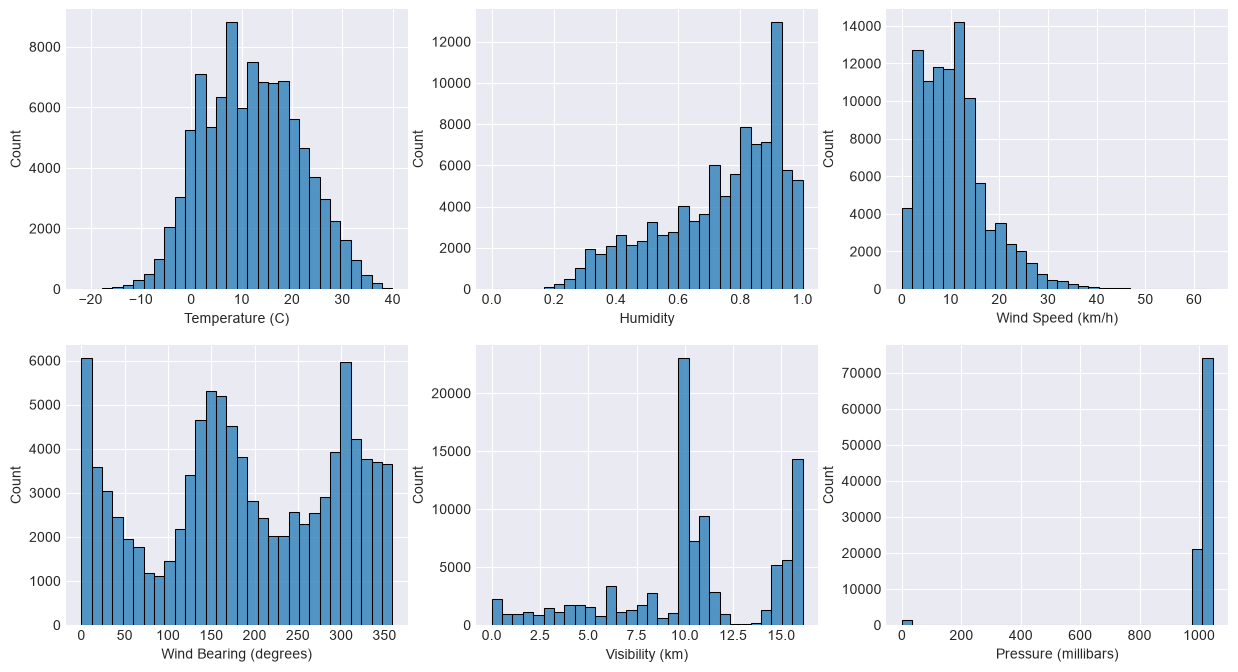

In [68]:
fig, axes = plt.subplots(2,3, figsize=(15,8))
axes= axes.ravel()
for count, col in enumerate(num_cols_df):
    ax=axes[count]
    sns.histplot(data = df, x = col, bins=30, ax=ax)

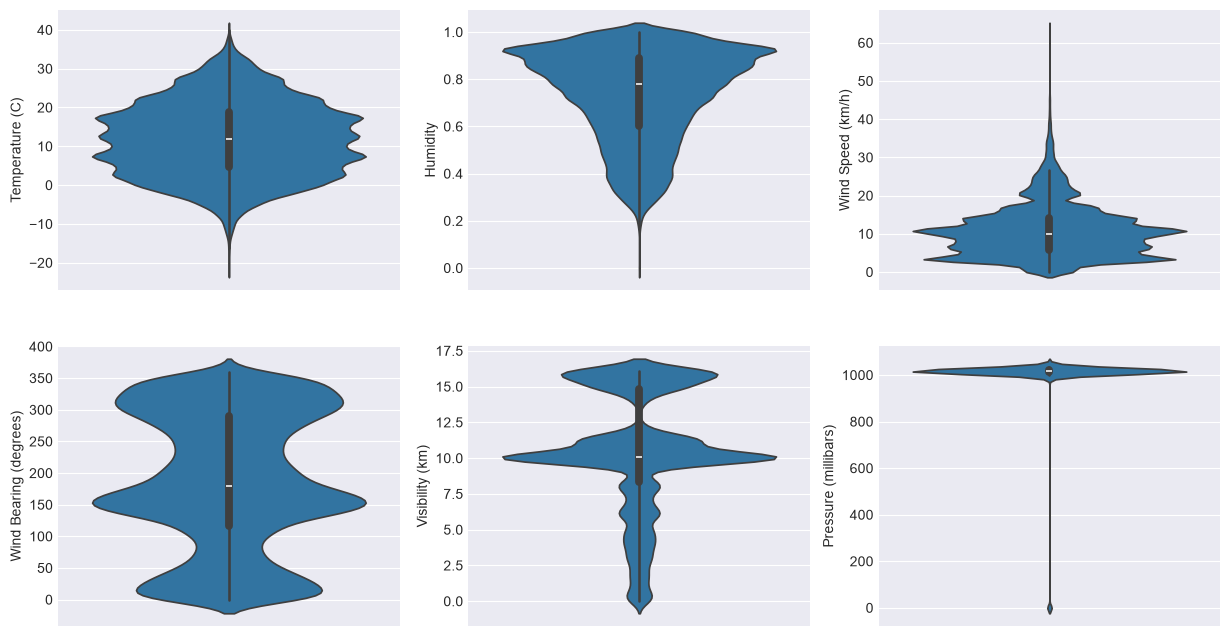

In [69]:
fig, axes = plt.subplots(2,3, figsize=(15,8))
axes= axes.ravel()
for count, col in enumerate(num_cols_df):
    ax=axes[count]
    sns.violinplot(data = df, y = col, ax=ax)

<Axes: >

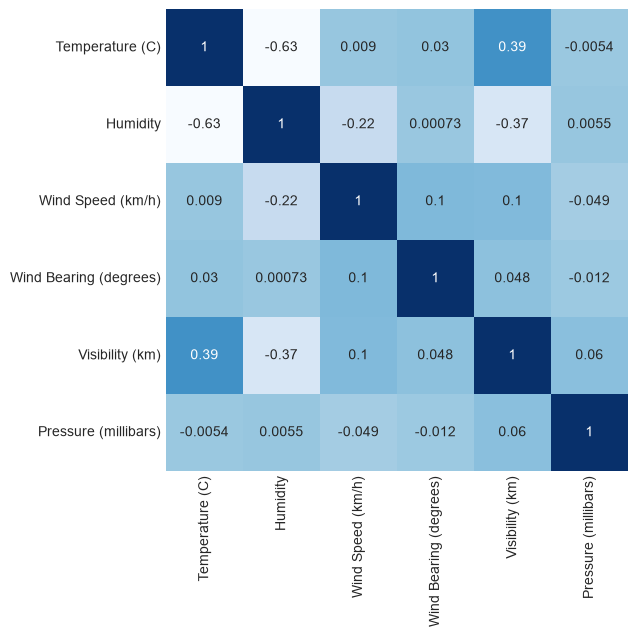

In [70]:
sns.heatmap(num_cols_df.corr(),cmap='Blues',annot=True, square=True,cbar=False)

In [71]:
temp_df=df[['datetime', 'Temperature (C)','Humidity', 'Wind Speed (km/h)']]
temp_df= temp_df.sort_values('datetime',axis=0).reset_index(drop=True)
temp_df.rename({'Temperature (C)':'temp','Wind Speed (km/h)':'wind'},axis=1,inplace=True)
temp_df.head()

,datetime,temp,Humidity,wind
0,2005-12-31 23:00:00+00:00,0.577778,0.89,17.1143
1,2006-01-01 00:00:00+00:00,1.161111,0.85,16.6152
2,2006-01-01 01:00:00+00:00,1.666667,0.82,20.2538
3,2006-01-01 02:00:00+00:00,1.711111,0.82,14.4900
4,2006-01-01 03:00:00+00:00,1.183333,0.86,13.9426


<Axes: xlabel='datetime'>

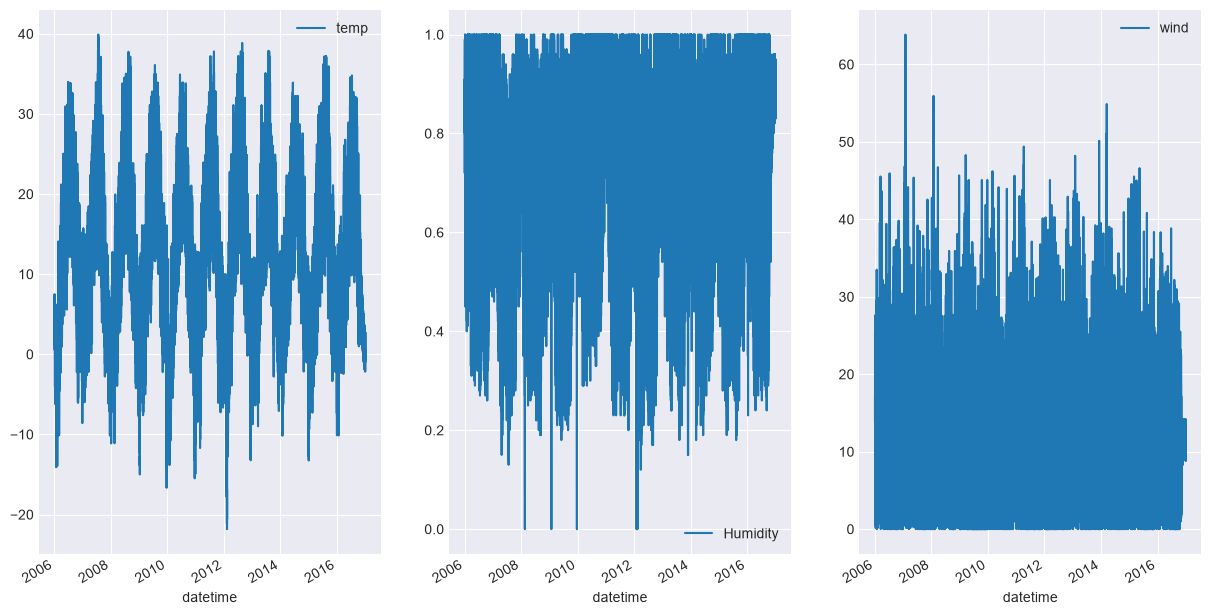

In [72]:
fig, axes = plt.subplots(1,3, figsize=(15,8))
temp_df.plot(kind='line',x='datetime',y='temp',ax=axes[0])

temp_df.plot(kind='line',x='datetime',y='Humidity',ax=axes[1])

temp_df.plot(kind='line',x='datetime',y='wind',ax=axes[2])

In [73]:
# h_units = 100
# input_shape = (1, 10000)
# model = tf.keras.Sequential()
# model.add(tf.keras.layers.Input(shape=input_shape))
# model.add(tf.keras.layers.SimpleRNN(units=h_units, activation='tanh'))
# model.add(tf.keras.layers.Dense(1))

In [74]:
# Wax=model.get_weights()[0].shape
# Waa=model.get_weights()[1].shape
# baa=model.get_weights()[2].shape
# Way=model.get_weights()[3].shape
# bay=model.get_weights()[4].shape

# print(f'Wax{Wax} ; Waa{Waa} ; baa{baa} ; Way{Way} : bay{bay}')

In [75]:
time_step=24
y_idx=np.arange(time_step, temp_df.shape[0],time_step)



In [76]:
y_df=temp_df.iloc[y_idx][['datetime','temp']]
y_df.head()

,datetime,temp
24,2006-01-01 23:00:00+00:00,5.422222
48,2006-01-02 23:00:00+00:00,1.694444
72,2006-01-03 23:00:00+00:00,2.200000
96,2006-01-04 23:00:00+00:00,1.666667
120,2006-01-05 23:00:00+00:00,1.805556


In [77]:
X_df= temp_df.iloc[range(len(y_df)*time_step)]
X_df.shape

(96432, 4)

In [78]:
X_temp=np.reshape(X_df['temp'].to_numpy(), (y_df.shape[0], time_step))
X_hum=np.reshape(X_df['Humidity'].to_numpy(), (y_df.shape[0], time_step))
X_wind=np.reshape(X_df['wind'].to_numpy(), (y_df.shape[0], time_step))
X_temp.shape, X_hum.shape, X_wind.shape

((4018, 24), (4018, 24), (4018, 24))

In [79]:
X_temp=X_temp[:,:23]
X_hum=X_hum[:,:23]
X_wind=X_wind[:,:23]
X_temp.shape

(4018, 23)

In [80]:
X_data=np.stack((X_temp, X_hum,X_wind),axis=2)
X_data.shape

(4018, 23, 3)

In [81]:
split= int(y_df.shape[0]*(1-TEST_SIZE))

X_train = X_data[:split]
X_test=X_data[split:]
y_train=y_df['temp'].to_numpy()[:split]
y_test=y_df['temp'].to_numpy()[split:]
print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(3214, 23, 3) (804, 23, 3) (3214,) (804,)


In [82]:
train_ds = tf.data.Dataset.from_tensor_slices((X_train,y_train))
train_ds = train_ds.cache()
train_ds = train_ds.shuffle(buffer_size=X_train.shape[0]).batch(BATCH_SIZE)
train_ds = train_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

In [83]:
test_ds = tf.data.Dataset.from_tensor_slices((X_test,y_test))
test_ds = test_ds.cache()
test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

In [87]:
h_units = 256
input_shape = (time_step-1, 3)
model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=input_shape))
model.add(tf.keras.layers.SimpleRNN(units=h_units, activation='tanh'))
model.add(tf.keras.layers.Dense(1))

In [88]:
model.compile(optimizer='adam',
            loss='mean_squared_error',
            metrics=[tf.keras.metrics.RootMeanSquaredError()]
)

In [89]:
history=model.fit(train_ds,
            validation_data=test_ds,
            epochs=EPOCHS
            )

Epoch 1/100


C:\Users\PGCP-AI\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - loss: 10.4409 - root_mean_squared_error: 3.2312 - val_loss: 1.2419 - val_root_mean_squared_error: 1.1144
Epoch 2/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 1.6849 - root_mean_squared_error: 1.2980 - val_loss: 1.0097 - val_root_mean_squared_error: 1.0049
Epoch 3/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 1.3389 - root_mean_squared_error: 1.1571 - val_loss: 0.9156 - val_root_mean_squared_error: 0.9569
Epoch 4/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 1.2739 - root_mean_squared_error: 1.1287 - val_loss: 0.9502 - val_root_mean_squared_error: 0.9748
Epoch 5/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 1.1429 - root_mean_squared_error: 1.0691 - val_loss: 0.7564 - val_root_mean_squared_error: 0.8697
Epoch 6/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 1.1462 - root_mean_squared_error: 1.0706 - val_loss: 0.8194 - val_root_mean_squared_error: 0.9052
Epoch 7/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/st

In [90]:
hist_df=pd.DataFrame(history.history)
hist_df.head()

,loss,root_mean_squared_error,val_loss,val_root_mean_squared_error
0,10.440937,3.231244,1.241944,1.114425
1,1.684894,1.298035,1.009748,1.004862
2,1.338889,1.157104,0.915598,0.956869
3,1.273865,1.128656,0.950208,0.974786
4,1.142870,1.069051,0.756365,0.869693


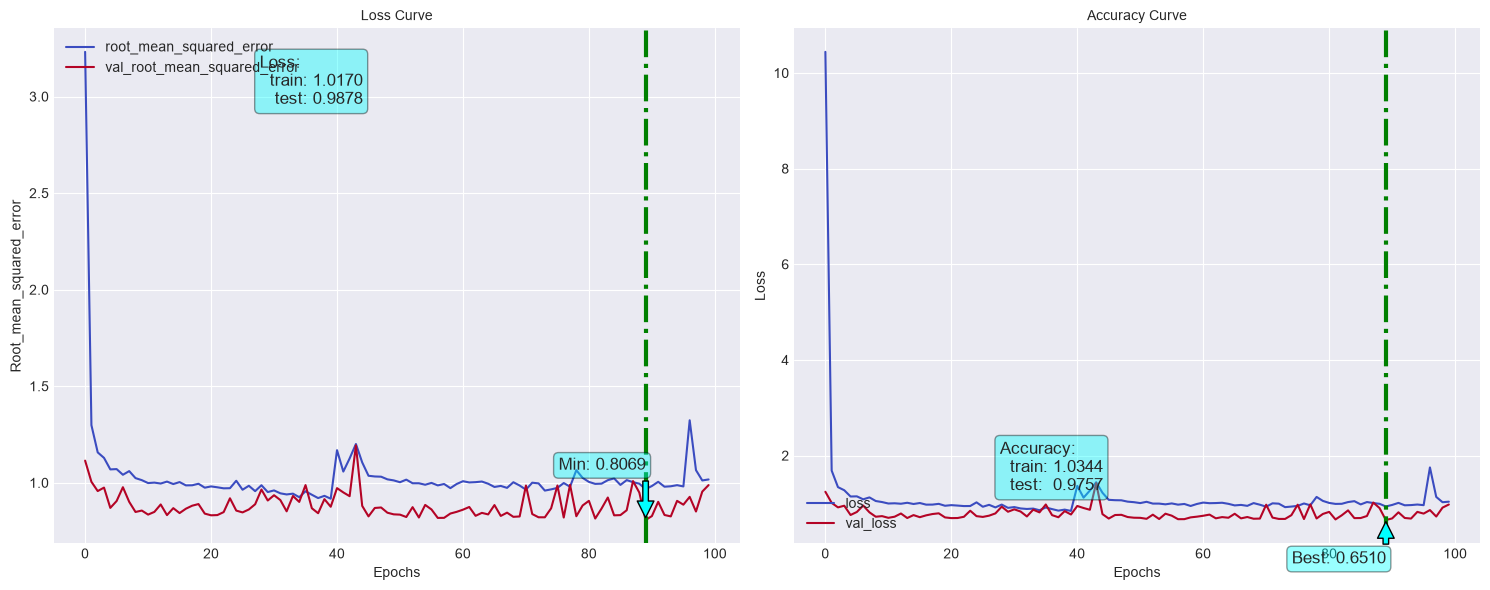

In [96]:
fn_plot_tf_hist(hist_df)

In [91]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)
y_pred = np.append(y_train_pred,y_test_pred)

101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


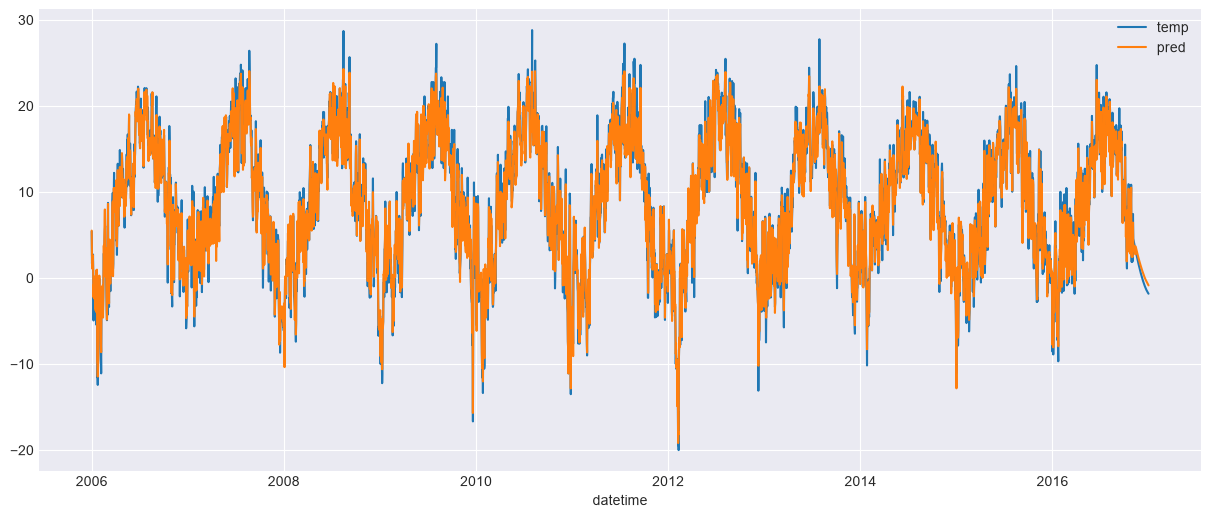

In [92]:
res_df=y_df.copy()
res_df['pred']=y_pred
res_df['datetime']=res_df['datetime'].dt.date
ax=res_df.plot(x='datetime',y=['temp','pred'])